# Q14 - K-means + KNN Semi-Supervised Learning for Cultural Tourism

Same code as `q14_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q14 - Semi-supervised clustering of tourist destinations (K-means + KNN) for cultural tours.

Numeric features are APPROXIMATE readings from Diagram 6 (Mastercard Global Destination Cities):
year-over-year growth (%), spend per visit ($) and visits (millions, from the bubble size).
Binary cultural attributes are our own assumptions. Mixed distance:
    d(a, b) = alpha * Euclidean(normalised numeric) + (1 - alpha) * Hamming(binary) / m
"""
import itertools
import math
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

ATTRS = ["heritage", "religious", "art", "street food", "shopping", "nightlife", "nature",
         "skyline"]
# city: (growth %, spend $, visits M, lat, lon, cultural bits in ATTRS order)
CITIES = {
    "Dubai": (7.0, 2000, 15.3, 25.2, 55.3, "00001111"),
    "New York": (3.0, 1600, 12.8, 40.7, -74.0, "00111101"),
    "Barcelona": (6.3, 1100, 8.2, 41.4, 2.2, "10100110"),
    "Taipei": (7.3, 1200, 6.0, 25.0, 121.6, "01011111"),
    "London": (7.6, 1150, 19.9, 51.5, -0.1, "10101100"),
    "Seoul": (10.2, 1150, 10.2, 37.6, 127.0, "10011101"),
    "Tokyo": (12.2, 1100, 11.7, 35.7, 139.7, "11111101"),
    "Milan": (1.8, 950, 7.7, 45.5, 9.2, "10101000"),
    "Singapore": (4.2, 1000, 12.1, 1.4, 103.8, "00011111"),
    "Kuala Lumpur": (7.5, 950, 12.0, 3.1, 101.7, "01011001"),
    "Hong Kong": (0.5, 850, 8.4, 22.3, 114.2, "00011111"),
    "Paris": (2.3, 800, 18.0, 48.9, 2.4, "10101100"),
    "Shanghai": (6.8, 800, 6.1, 31.2, 121.5, "10011101"),
    "Istanbul": (0.5, 650, 12.0, 41.0, 29.0, "11110010"),
    "Rome": (2.3, 650, 7.1, 41.9, 12.5, "11100000"),
    "Vienna": (7.6, 650, 6.7, 48.2, 16.4, "11100100"),
    "Bangkok": (9.6, 700, 21.5, 13.8, 100.5, "11011100"),
    "Amsterdam": (2.9, 550, 8.0, 52.4, 4.9, "10100110"),
    "Prague": (1.5, 500, 6.0, 50.1, 14.4, "11100100"),
    "Osaka": (13.4, 550, 9.4, 34.7, 135.5, "10011000"),
}
NAMES = list(CITIES)
RAW = np.array([CITIES[c][:3] for c in NAMES], dtype=float)
LO, HI = RAW.min(axis=0), RAW.max(axis=0)
NUM = (RAW - LO) / (HI - LO)                      # min-max normalised numeric part
BIN = np.array([[int(b) for b in CITIES[c][5]] for c in NAMES])
ALPHA, K = 0.3, 4                                 # culture (binary part) gets 70% of the weight
SEEDS = {"Rome": "Heritage & Faith", "Paris": "Art & Lifestyle",
         "Bangkok": "Street Food & Markets", "Dubai": "Modern & Shopping"}


def mixed_distance(a_num: np.ndarray, a_bin: np.ndarray, b_num: np.ndarray,
                   b_bin: np.ndarray) -> float:
    euclid = np.linalg.norm(a_num - b_num) / math.sqrt(a_num.size)   # scaled to 0..1
    hamming = np.abs(a_bin - b_bin).sum() / a_bin.size              # 0..1
    return ALPHA * euclid + (1 - ALPHA) * hamming


def dist(i: int, j: int) -> float:
    return mixed_distance(NUM[i], BIN[i], NUM[j], BIN[j])


def kmeans_mixed(k: int, n_init: int = 10, seed: int = 3) -> tuple:
    """K-means for mixed data: numeric centre = mean, binary centre = majority vote."""
    rng, best = np.random.default_rng(seed), None
    for _ in range(n_init):
        idx = rng.choice(len(NAMES), k, replace=False)
        c_num, c_bin = NUM[idx].copy(), BIN[idx].copy()
        for _ in range(20):
            d = np.array([[mixed_distance(NUM[i], BIN[i], c_num[j], c_bin[j])
                           for j in range(k)] for i in range(len(NAMES))])
            assign = d.argmin(axis=1)
            for j in range(k):
                if (assign == j).any():
                    c_num[j] = NUM[assign == j].mean(axis=0)
                    c_bin[j] = (BIN[assign == j].mean(axis=0) >= 0.5).astype(int)
        cost = d.min(axis=1).sum()
        if best is None or cost < best[0]:
            best = (cost, assign.copy(), c_num.copy(), c_bin.copy())
    return best[1], best[2], best[3]


def name_clusters(c_num: np.ndarray, c_bin: np.ndarray) -> dict:
    """Give each cluster the seed label whose city is closest to its centre (1-to-1)."""
    seeds = list(SEEDS)
    cost = lambda perm: sum(mixed_distance(c_num[j], c_bin[j], NUM[NAMES.index(s)],
                                           BIN[NAMES.index(s)]) for j, s in enumerate(perm))
    perm = min(itertools.permutations(seeds), key=cost)
    return {j: SEEDS[s] for j, s in enumerate(perm)}


def knn_refine(labels: list, k: int = 3, max_rounds: int = 5) -> tuple:
    """KNN with the mixed distance re-checks every pseudo-label; the 4 seeds never change."""
    labels, history = list(labels), []
    for _ in range(max_rounds):
        changed = []
        for i, city in enumerate(NAMES):
            if city in SEEDS:
                continue
            near = sorted((j for j in range(len(NAMES)) if j != i), key=lambda j: dist(i, j))[:k]
            votes = [labels[j] for j in near]
            top = max(set(votes), key=votes.count)
            if votes.count(top) >= 2 and top != labels[i]:   # clear majority disagrees
                changed.append((i, top))
        for i, top in changed:
            history.append(f"{NAMES[i]}: {labels[i]} -> {top}")
            labels[i] = top
        if not changed:
            break
    return labels, history


assign, c_num, c_bin = kmeans_mixed(K)
names = name_clusters(c_num, c_bin)
pseudo = [names[a] for a in assign]               # cluster-then-label
print(f"STEP 1-2  K-means (k={K}, alpha={ALPHA}) on 20 unlabelled cities, named by 4 seeds")
print("  seeds (4 of 20, one per category):", ", ".join(SEEDS))
r, pr, du = (NAMES.index(c) for c in ("Rome", "Prague", "Dubai"))
print(f"  mixed distance: d(Rome, Prague) = {dist(r, pr):.3f}, d(Rome, Dubai) = {dist(r, du):.3f}")
for j in range(K):
    traits = ", ".join(ATTRS[t] for t in range(len(ATTRS)) if c_bin[j][t])
    print(f"  {names[j]:<21} centre: {traits}")
final, history = knn_refine(pseudo)
print("STEP 3  KNN (k=3, mixed distance) re-checks the pseudo-labels")
for line in history or ["no changes"]:
    print("  moved", line)
groups = {lab: [NAMES[i] for i in range(len(NAMES)) if final[i] == lab] for lab in SEEDS.values()}
print("STEP 4  Final cultural clusters")
for lab, members in groups.items():
    print(f"  {lab:<21}: {', '.join(members)}")

# ---- new destinations: KNN only (assumed values) ----
NEW = {"Kyoto": (8.0, 700, 6.0, "11110010"), "Lisbon": (6.0, 600, 5.0, "10100110")}
for city, (g, s, v, bits) in NEW.items():
    n = (np.array([g, s, v]) - LO) / (HI - LO)
    b = np.array([int(x) for x in bits])
    near = sorted(range(len(NAMES)), key=lambda j: mixed_distance(n, b, NUM[j], BIN[j]))[:3]
    labs = [final[j] for j in near]
    print(f"STEP 5  new city {city:<7} -> {max(set(labs), key=labs.count)}"
          f"  (3 nearest: {', '.join(NAMES[j] for j in near)})")

# ---- systemic creativity: bridge cities sit between two cultural clusters ----
cent_d = np.array([[mixed_distance(NUM[i], BIN[i], c_num[j], c_bin[j]) for j in range(K)]
                   for i in range(len(NAMES))])
two = np.sort(cent_d, axis=1)[:, :2]
bridge = sorted(range(len(NAMES)), key=lambda i: -two[i, 0] / two[i, 1])[:3]
print("Bridge cities (closest to two clusters):",
      ", ".join(f"{NAMES[i]} ({two[i, 0] / two[i, 1]:.2f})" for i in bridge))

# ---- organise a tour for a culture-loving traveller ----
PROFILE = np.array([1, 1, 1, 0, 0, 0, 1, 0])      # heritage, religious, art, nature
BUDGET = 1200
match = 1 - np.abs(BIN - PROFILE).sum(axis=1) / len(ATTRS)
best_lab = max(groups, key=lambda lab: np.mean([match[NAMES.index(c)] for c in groups[lab]]))
stops = [c for c in groups[best_lab] if CITIES[c][1] <= BUDGET]
others = [c for c in NAMES if final[NAMES.index(c)] != best_lab and CITIES[c][1] <= BUDGET]
extra = max(others, key=lambda c: match[NAMES.index(c)])
stops.append(extra)                                # one cross-cluster stop (systemic idea)


def km(a: str, b: str) -> float:
    (la, oa), (lb, ob) = CITIES[a][3:5], CITIES[b][3:5]
    la, lb, dl = map(math.radians, (la, lb, ob - oa))
    return 6371 * math.acos(min(1, math.sin(la) * math.sin(lb)
                                + math.cos(la) * math.cos(lb) * math.cos(dl)))


route = [max(stops, key=lambda c: match[NAMES.index(c)])]
while len(route) < len(stops):                     # nearest-neighbour ordering
    route.append(min((c for c in stops if c not in route), key=lambda c: km(route[-1], c)))
total = sum(km(a, b) for a, b in zip(route, route[1:]))
print(f"STEP 6  traveller 'culture lover' -> cluster {best_lab}, cross-cluster stop {extra}")
print("  match:", ", ".join(f"{c} {match[NAMES.index(c)]:.2f}" for c in route))
print(f"  tour ({len(route)} stops, {total:,.0f} km): {' -> '.join(route)}")

# ---------------- charts ----------------
COL = {"Heritage & Faith": "#c8553d", "Art & Lifestyle": "#7b5ea7",
       "Street Food & Markets": "#2a9d8f", "Modern & Shopping": "#3a6ea5"}
fig, ax = plt.subplots(figsize=(9.5, 5.6))
for i, c in enumerate(NAMES):
    g, s, v = CITIES[c][:3]
    ax.scatter(g, s, s=v * 70, color=COL[final[i]], alpha=0.75, edgecolor="white", lw=1.5)
    ax.annotate(c, (g, s), fontsize=7.5, ha="center", va="center")
ax.axvline(7, color="#555", lw=0.8)
ax.axhline(1000, color="#555", lw=0.8)
for lab, col in COL.items():
    ax.scatter([], [], s=80, color=col, label=lab)
ax.legend(loc="upper right", fontsize=8, title="cultural cluster (K-means + KNN)")
ax.set_xlabel("year-over-year growth 2015-16 (%)  [approx. reading of Diagram 6]")
ax.set_ylabel("spend per visit ($)")
ax.set_title("Diagram 6 re-coloured: cultural clusters instead of regions")
ax.set_xlim(-1, 15)
ax.set_ylim(300, 2250)
fig.tight_layout()
fig.savefig("images/q14_chart1_cultural_clusters.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
for value in sorted(set(match)):                  # spread cities that share a match value
    same = sorted((i for i in range(len(NAMES)) if match[i] == value),
                  key=lambda i: CITIES[NAMES[i]][1])
    for rank, i in enumerate(same):
        c = NAMES[i]
        x = value + 0.04 * (rank - (len(same) - 1) / 2)
        y = CITIES[c][1]
        ax.scatter(x, y, s=CITIES[c][2] * 40, color=COL[final[i]], alpha=0.75,
                   edgecolor="black" if c in route else "white", lw=2 if c in route else 1.2)
        up = rank % 2 == 0
        ax.annotate(c, (x, y), textcoords="offset points", xytext=(0, 13 if up else -15),
                    fontsize=7.5, ha="center", va="center")
ax.axvline(0.66, color="#555", lw=0.8, ls="--")
ax.axhline(BUDGET, color="#555", lw=0.8, ls="--")
ax.text(1.04, BUDGET + 40, "sweet spot: high match, in budget", fontsize=8, ha="right",
        color="#7c2d12")
for lab, col in COL.items():
    ax.scatter([], [], s=80, color=col, label=lab)
ax.legend(loc="upper left", fontsize=8)
ax.set_xlabel("cultural-preference match with the traveller (1 - Hamming/8)")
ax.set_ylabel("spend per visit ($)")
ax.set_title("Diagram 6 modified: distribution by cultural preference (black ring = on tour)")
ax.set_xlim(0, 1.05)
ax.set_ylim(300, 2250)
fig.tight_layout()
fig.savefig("images/q14_chart2_preference_distribution.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
for c in NAMES:
    la, lo = CITIES[c][3:5]
    if -12 < lo < 35 and 35 < la < 56:
        on = c in route
        ax.scatter(lo, la, s=120 if on else 40, color=COL[final[NAMES.index(c)]],
                   alpha=1 if on else 0.35, zorder=3)
        ax.annotate(c, (lo, la), textcoords="offset points", xytext=(6, 5), fontsize=8,
                    color="#111" if on else "#888")
for n, (a, b) in enumerate(zip(route, route[1:]), start=1):
    (la1, lo1), (la2, lo2) = CITIES[a][3:5], CITIES[b][3:5]
    ax.annotate("", (lo2, la2), (lo1, la1),
                arrowprops=dict(arrowstyle="-|>", color="#c8553d", lw=2), zorder=2)
    ax.text((lo1 + lo2) / 2, (la1 + la2) / 2, str(n), fontsize=9, color="white",
            ha="center", va="center", bbox=dict(boxstyle="circle", fc="#c8553d", ec="none"))
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_xlim(-8, 34)
ax.set_ylim(36, 55)
ax.set_title(f"Cultural tour (nearest-neighbour order), {total:,.0f} km")
fig.tight_layout()
fig.savefig("images/q14_chart3_tour_route.png")
plt.close(fig)
print("charts saved to images/")


STEP 1-2  K-means (k=4, alpha=0.3) on 20 unlabelled cities, named by 4 seeds
  seeds (4 of 20, one per category): Rome, Paris, Bangkok, Dubai
  mixed distance: d(Rome, Prague) = 0.111, d(Rome, Dubai) = 0.804
  Art & Lifestyle       centre: heritage, art, shopping, nightlife
  Street Food & Markets centre: heritage, religious, street food, shopping, nightlife, skyline
  Heritage & Faith      centre: heritage, religious, art, nightlife
  Modern & Shopping     centre: street food, shopping, nightlife, nature, skyline
STEP 3  KNN (k=3, mixed distance) re-checks the pseudo-labels
  moved Barcelona: Art & Lifestyle -> Heritage & Faith
  moved Kuala Lumpur: Street Food & Markets -> Modern & Shopping
  moved Shanghai: Street Food & Markets -> Modern & Shopping
STEP 4  Final cultural clusters
  Heritage & Faith     : Barcelona, Istanbul, Rome, Vienna, Amsterdam, Prague
  Art & Lifestyle      : London, Milan, Paris
  Street Food & Markets: Seoul, Tokyo, Bangkok, Osaka
  Modern & Shopping    : Du

charts saved to images/


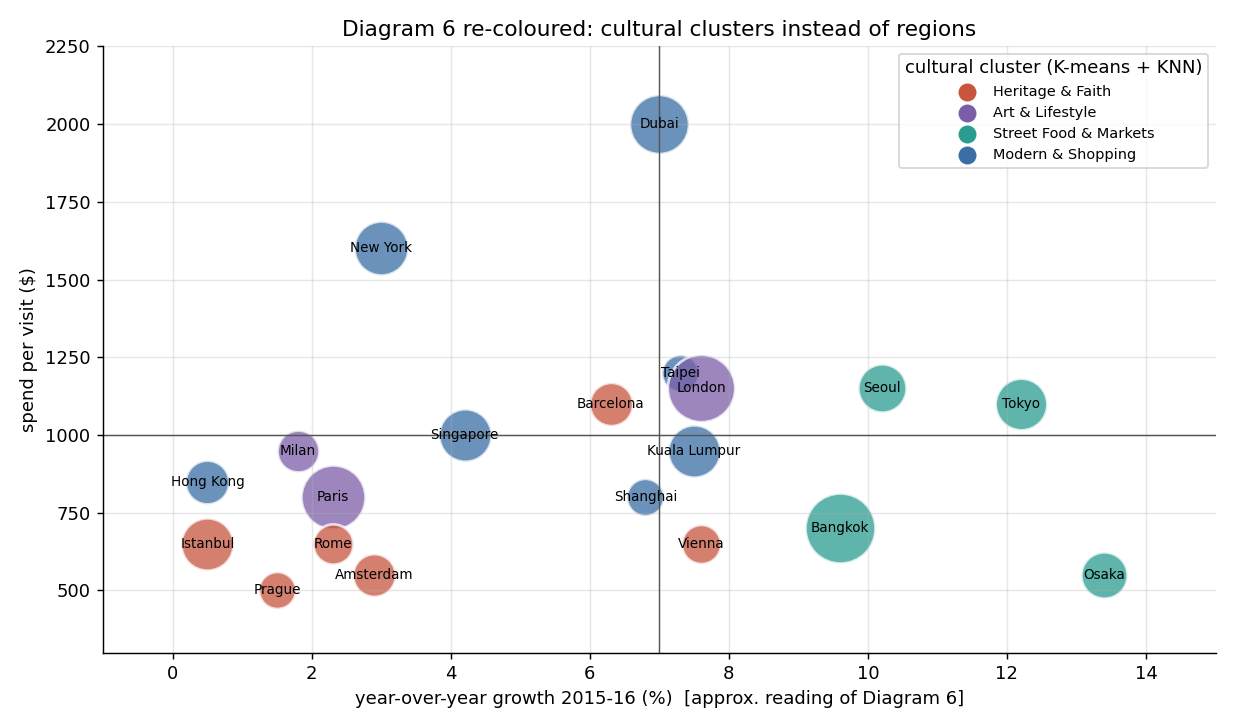

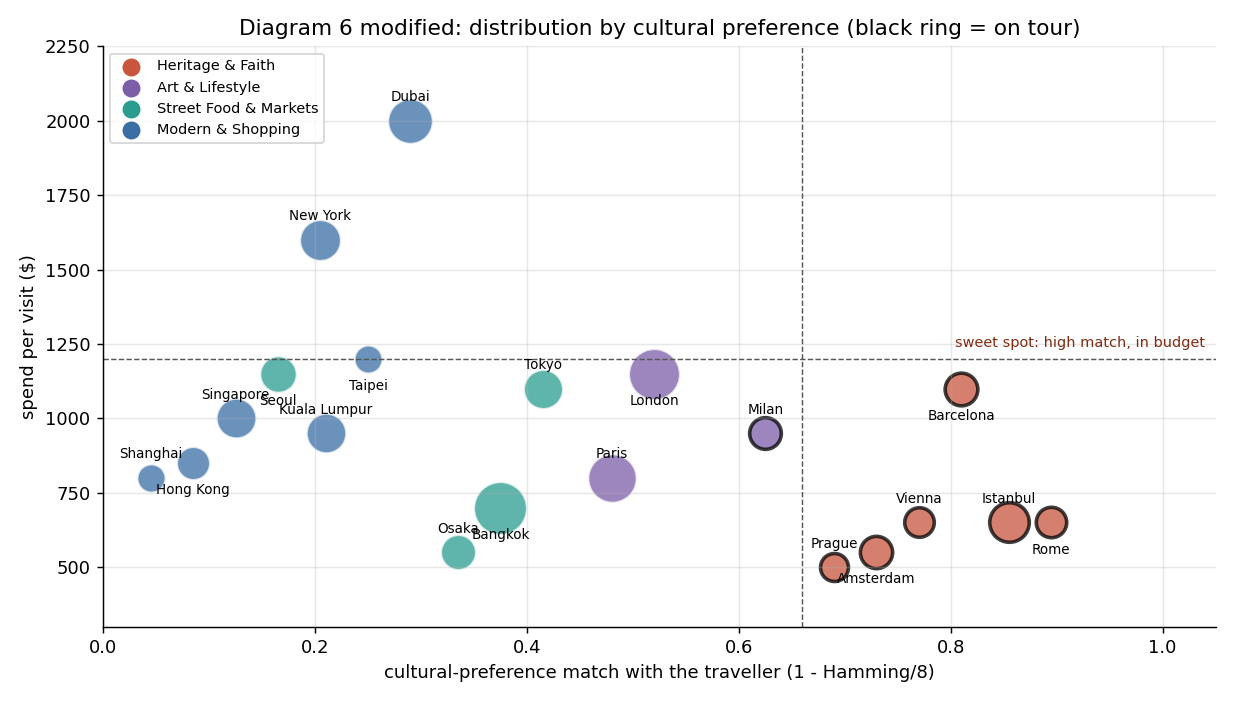

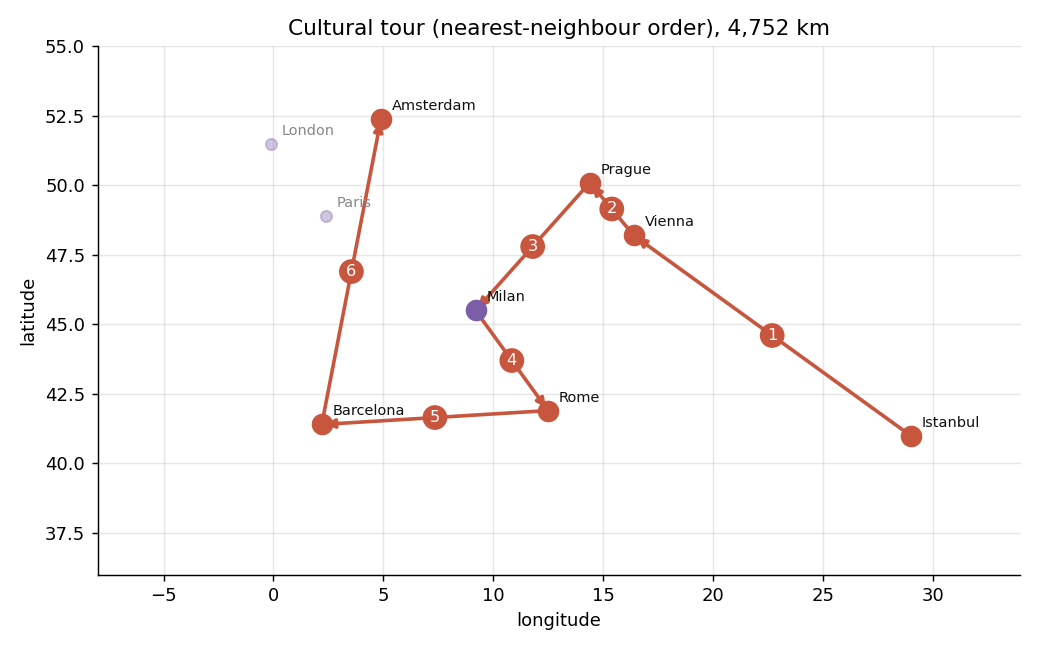

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q14_chart*.png')):
    display(Image(p))